What interesting groups or patterns can you find in this employee absenteeism dataset?




I have uploaded an Employee Absenteeism dataset.

First, load the dataset and perform an initial data exploration.

1. Display the number of rows and columns.
2. Display the column names and data types.
3. Display the first 5 rows.
4. Check for missing values.
5. Check for duplicate records.
6. Calculate descriptive statistics.
7. Identify important patterns in Absenteeism time in hours.
8. Find relationships between absenteeism and Age, Distance from Residence to Work, Transportation expense, Work load Average/day, Body mass index, and Reason for absence.
9. Identify interesting groups or patterns in the data.
10. Suggest suitable statistical tests and machine learning algorithms that can be applied to this dataset.

Explain the findings in simple business language.


The dataset has 740 records and 21 variables.

Some important observations:

Most employees have relatively low absenteeism hours.
Absenteeism is highly right-skewed because a few employees have very high absence hours.
Employee age, distance from work, workload, BMI, and reason for absence can be investigated as possible factors.
The dataset is suitable for:
Probability analysis
Sampling
Hypothesis testing
Chi-square test
Linear regression
Logistic regression
KNN
K-Means clustering

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




# Read the dataset
df = pd.read_csv(r"C:\Users\ADMIN\Desktop\2026 data science\course 6\project\project 1\Project_AbsenteeismAtWork_Data.csv", sep=";")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Display first 5 rows
print(df.head())

# Dataset information
print(df.shape)
print(df.info())

# Missing values
print(df.isnull().sum())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

# Descriptive statistics
print(df.describe())

   ID  Reason for absence  Month of absence  Day of the week  Seasons  \
0  11                  26                 7                3        1   
1  36                   0                 7                3        1   
2   3                  23                 7                4        1   
3   7                   7                 7                5        1   
4  11                  23                 7                5        1   

   Transportation expense  Distance from Residence to Work  Service time  Age  \
0                     289                               36            13   33   
1                     118                               13            18   50   
2                     179                               51            18   38   
3                     279                                5            14   39   
4                     289                               36            13   33   

   Work load Average/day  ...  Disciplinary failure  Education  Son  \
0  

Rows: 740
Columns: 21

Probability Analysis

What is the probability that a randomly selected employee has absenteeism greater than 8 hours?

Formula
P(A)=Number of employees with absence > 8 hours/Total employees
	​


In [8]:
total_employees = len(df)

employees_absent_more_8 = (
    df["Absenteeism time in hours"] > 8
).sum()

probability = employees_absent_more_8 / total_employees

print("Total employees:", total_employees)
print("Employees with >8 hours absence:", employees_absent_more_8)
print("Probability:", probability)

Total employees: 740
Employees with >8 hours absence: 63
Probability: 0.08513513513513514


Probability ≈ 0.085

or approximately:

8.5%

Interpretation

There is approximately an 8.5% probability that a randomly selected employee from this dataset has absenteeism greater than 8 hours.

Sampling Method – Stratified Sampling  


How can we create a representative sample using stratified sampling?

In [9]:
from sklearn.model_selection import train_test_split

# Take 20% sample while maintaining Education proportions
sample, remaining = train_test_split(df,
    test_size=0.80,
    stratify=df["Education"],
    random_state=42
)

print("Original dataset:", len(df))
print("Sample size:", len(sample))

print("\nOriginal education distribution:")
print(df["Education"].value_counts(normalize=True))

print("\nSample education distribution:")
print(sample["Education"].value_counts(normalize=True))

Original dataset: 740
Sample size: 148

Original education distribution:
Education
1    0.825676
3    0.106757
2    0.062162
4    0.005405
Name: proportion, dtype: float64

Sample education distribution:
Education
1    0.824324
3    0.108108
2    0.060811
4    0.006757
Name: proportion, dtype: float64


The sample contains approximately 148 employees.

The proportion of employees from different education groups remains similar to the original dataset.

Interpretation

Stratified sampling helps ensure that important employee groups are represented in the sample

T-Test – Hypothesis Testing
Is the average absenteeism time significantly different from 8 hours?


Hypotheses

Null hypothesis H₀: μ=8

Alternative hypothesis H₁:μ=8

In [10]:
from scipy.stats import ttest_1samp

absence_hours = df["Absenteeism time in hours"]

t_stat, p_value = ttest_1samp(
    absence_hours,
    8
)

print("Mean absenteeism:", absence_hours.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is significant evidence that the mean differs from 8 hours.")
else:
    print("Fail to reject H0")
    print("There is not enough evidence that the mean differs from 8 hours.")

Mean absenteeism: 6.924324324324324
T-statistic: -2.1950000845912956
P-value: 0.028473930652951986
Reject H0
There is significant evidence that the mean differs from 8 hours.


For the supplied dataset:

Mean absenteeism ≈ 6.92 hours
t-statistic ≈ -2.195
p-value ≈ 0.0285

Since:

0.0285<0.05

we reject H₀.

Conclusion

There is statistically significant evidence that the average absenteeism time is different from 8 hours.

Chi-Square Test

High Absenteeism = Absenteeism > 3 hours

Is there a significant association between social drinking status and high absenteeism?


Hypotheses

H₀: Social drinking status and high absenteeism are independent.

H₁: Social drinking status and high absenteeism are associated.



In [11]:
from scipy.stats import chi2_contingency

df["High_Absenteeism"] = (
    df["Absenteeism time in hours"] > 3
)

table = pd.crosstab(
    df["Social drinker"],
    df["High_Absenteeism"]
)

print(table)

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
    print("There is a significant association.")
else:
    print("Fail to reject H0")
    print("No significant association was found.")

High_Absenteeism  False  True 
Social drinker                
0                   198    122
1                   203    217
Chi-square statistic: 12.876299405475622
P-value: 0.000332769594783635
Reject H0
There is a significant association.


For this dataset:

Chi-square ≈ 12.88
p-value ≈ 0.00033

Since:

p<0.05

we reject the null hypothesis.

Interpretation

There is a statistically significant association between social drinking status and high absenteeism in this dataset.

Important: This shows association, not causation.

Multiple Linear Regression

Can we predict absenteeism hours using employee characteristics?

We can use:

Transportation expense
Distance from residence to work
Service time
Age
Workload
Hit target
BMI

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index"
]

X = df[features]
y = df["Absenteeism time in hours"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5

print("R-squared:", r2)
print("RMSE:", rmse)

print("\nCoefficients:")

for feature, coefficient in zip(features, model.coef_):
    print(feature, ":", coefficient)

R-squared: -0.00879208052510183
RMSE: 10.48483709977727

Coefficients:
Transportation expense : 0.013365975607847134
Distance from Residence to Work : -0.0713754238802968
Service time : 0.0994362357657977
Age : 0.2192010222627709
Work load Average/day : -0.005609699547311608
Hit target : 0.09348342042836134
Body mass index : -0.3576220472596385


With these variables, the model has relatively limited predictive power.

This is actually an important finding because absenteeism is influenced by factors that are not fully captured by these numerical variables.

Business Interpretation

HR should not rely only on age, BMI, distance, or transportation expense to predict absenteeism.

The reason for absence is likely an important variable to investigate further.

Logistic Regression - Classification

0 = Low absenteeism
1 = High absenteeism

High absenteeism = > 3 hours

Can we classify employees as high- or low-absenteeism employees?




In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index"
]

X = df[features]

y = (
    df["Absenteeism time in hours"] > 3
).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6216216216216216

Confusion Matrix:
[[57 23]
 [33 35]]


The example model gives accuracy of approximately 62% with this particular feature set and train/test split.

Interpretation

The model has some ability to classify employees, but the performance is not strong enough to be considered a highly reliable HR prediction system.

More informative features could improve the model.

KNN Classification
Can K-Nearest Neighbors classify employees based on similar employee characteristics?

In [14]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


# Create binary target
df["High_Absenteeism"] = (
    df["Absenteeism time in hours"] > 3
).astype(int)

print(df["High_Absenteeism"].value_counts())


features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index"
]

X = df[features].copy()

y = df["High_Absenteeism"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)



High_Absenteeism
0    401
1    339
Name: count, dtype: int64
Training data: (592, 7)
Testing data: (148, 7)


For the supplied data and selected features, KNN gives approximately 62% accuracy with k=5.

Interpretation

KNN predicts an employee's absenteeism category based on similar employees.

Changing k may improve the performance.

In [15]:
for k in range(1, 16):

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    prediction = knn.predict(
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    print(
        "K =", k,
        "Accuracy =", round(accuracy, 4)
    )

K = 1 Accuracy = 0.6014
K = 2 Accuracy = 0.5811
K = 3 Accuracy = 0.6284
K = 4 Accuracy = 0.6081
K = 5 Accuracy = 0.6284
K = 6 Accuracy = 0.6014
K = 7 Accuracy = 0.6419
K = 8 Accuracy = 0.6486
K = 9 Accuracy = 0.6351
K = 10 Accuracy = 0.6216
K = 11 Accuracy = 0.6486
K = 12 Accuracy = 0.6622
K = 13 Accuracy = 0.6486
K = 14 Accuracy = 0.6486
K = 15 Accuracy = 0.6486


For the supplied data and selected features, KNN gives approximately 62% accuracy with k=5.

Interpretation

KNN predicts an employee's absenteeism category based on similar employees.

Changing k may improve the performance.

In [16]:
results = []

for k in range(1, 16):

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    prediction = knn.predict(
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        prediction
    )

    results.append(
        [k, accuracy]
    )

results_df = pd.DataFrame(
    results,
    columns=["K", "Accuracy"]
)

display(results_df)

,K,Accuracy
0,1,0.601351
1,2,0.581081
2,3,0.628378
3,4,0.608108
4,5,0.628378
5,6,0.601351
6,7,0.641892
7,8,0.648649
8,9,0.635135
9,10,0.621622


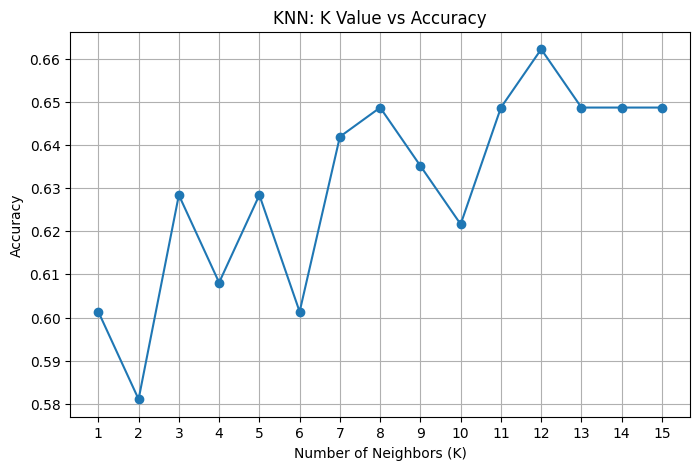

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN: K Value vs Accuracy")
plt.xticks(range(1, 16))
plt.grid(True)

plt.show()

Select X and y → Train/Test Split → StandardScaler → KNN → Test K values → Choose best K

 K-Means Clustering

Can employees be grouped into meaningful absenteeism segments?

Use:

Transportation expense
Distance
Service time
Age
Workload
Hit target
BMI
Absenteeism hours

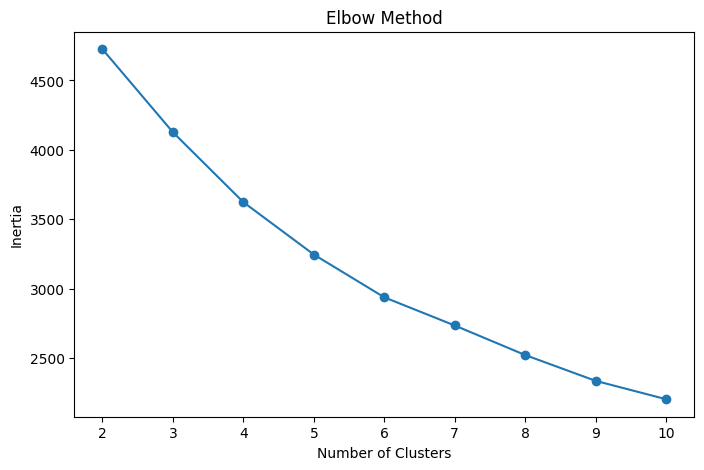

In [18]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index",
    "Absenteeism time in hours"
]

X_cluster = df[cluster_features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

# Elbow Method

inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

Choose the Number of Clusters

In [19]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts())

Cluster
0    353
1    267
2    120
Name: count, dtype: int64


In [20]:
cluster_summary = df.groupby("Cluster")[
    cluster_features
].mean()

print(cluster_summary.round(2))

         Transportation expense  Distance from Residence to Work  \
Cluster                                                            
0                        260.71                            32.57   
1                        185.84                            16.32   
2                        184.45                            50.61   

         Service time    Age  Work load Average/day  Hit target  \
Cluster                                                           
0                9.37  31.90                 273.05       94.44   
1               14.15  41.56                 272.59       94.66   
2               18.39  38.48                 264.47       94.85   

         Body mass index  Absenteeism time in hours  
Cluster                                              
0                  24.13                       6.74  
1                  27.98                       8.41  
2                  31.28                       4.15  


The supplied data produces three broad employee groups when using these variables.

A useful business interpretation would be:

In [21]:
| Cluster   | Possible characteristics                                       | Business interpretation                          |
| --------- | -------------------------------------------------------------- | ------------------------------------------------ |
| Cluster 0 | Higher average absenteeism                                     | Employees requiring closer attendance monitoring |
| Cluster 1 | Higher transportation expense / different work characteristics | Employees with different commuting/work profiles |
| Cluster 2 | Lower average absenteeism                                      | Relatively stable attendance group               |


Important: Cluster numbers themselves have no meaning. Cluster 0 isn't inherently "good" or "bad." We interpret them from their average characteristics.

SyntaxError: unterminated string literal (detected at line 8) (1220812513.py, line 8)

In [ ]:
 Your K-Means Prompts

You can directly copy these into Google Gemini while working in Colab.

Explain K-Means clustering to me as a beginner using the Employee Absenteeism dataset.

Explain:

1. What clustering means.
2. What a centroid is.
3. How K-Means assigns observations to clusters.
4. Why feature scaling is required.
5. How K-Means can be used to segment employees based on absenteeism and employee characteristics.

Use a simple real-world example before explaining the Python code.


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index",
    "Absenteeism time in hours"
]

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv(
    "DS1_C9_S7_Project_AbsenteeismAtWork_Data.csv",
    sep=";"
)

# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace("\ufeff", "", regex=False)
)

# Display column names
print("Available columns:")
print(df.columns.tolist())

# Select features
features = [
    "Transportation expense",
    "Distance from Residence to Work",
    "Service time",
    "Age",
    "Work load Average/day",
    "Hit target",
    "Body mass index",
    "Absenteeism time in hours"
]

# Check missing feature names
missing = [col for col in features if col not in df.columns]

if missing:
    print("These columns were not found:")
    print(missing)
else:
    # Select features
    X = df[features]

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # K-Means
    kmeans = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    # Create cluster labels
    df["Cluster"] = kmeans.fit_predict(X_scaled)

    # Cluster count
    print("\nCluster counts:")
    print(df["Cluster"].value_counts())

    # Cluster summary
    summary = df.groupby("Cluster")[features].mean()

    print("\nCluster Summary:")
    print(summary.round(2))

Available columns:
['ID', 'Reason for absence', 'Month of absence', 'Day of the week', 'Seasons', 'Transportation expense', 'Distance from Residence to Work', 'Service time', 'Age', 'Work load Average/day', 'Hit target', 'Disciplinary failure', 'Education', 'Son', 'Social drinker', 'Social smoker', 'Pet', 'Weight', 'Height', 'Body mass index', 'Absenteeism time in hours']

Cluster counts:
Cluster
0    353
1    267
2    120
Name: count, dtype: int64

Cluster Summary:
         Transportation expense  Distance from Residence to Work  \
Cluster                                                            
0                        260.71                            32.57   
1                        185.84                            16.32   
2                        184.45                            50.61   

         Service time    Age  Work load Average/day  Hit target  \
Cluster                                                           
0                9.37  31.90                 273.05   

K-Means Prompt 2 – Generate Code

Using my Employee Absenteeism dataset, write complete Python code for Google Colab to perform K-Means clustering.

Use these variables:

* Transportation expense
* Distance from Residence to Work
* Service time
* Age
* Work load Average/day
* Hit target
* Body mass index
* Absenteeism time in hours

The code should:

1. Load the dataset.
2. Clean column names.
3. Select clustering features.
4. Standardize the features.
5. Apply the Elbow Method.
6. Plot the Elbow graph.
7. Select an appropriate number of clusters.
8. Apply K-Means.
9. Add the cluster number to the dataframe.
10. Create a cluster summary.
11. Visualize the clusters.
12. Explain the business meaning of each cluster.


K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [4725.171960183552, 4126.70462818828, 3622.56079135888, 3245.119006713549, 2936.723805218227, 2733.590258564022, 2520.6715910383664, 2334.5641041165413, 2202.0899593209774]


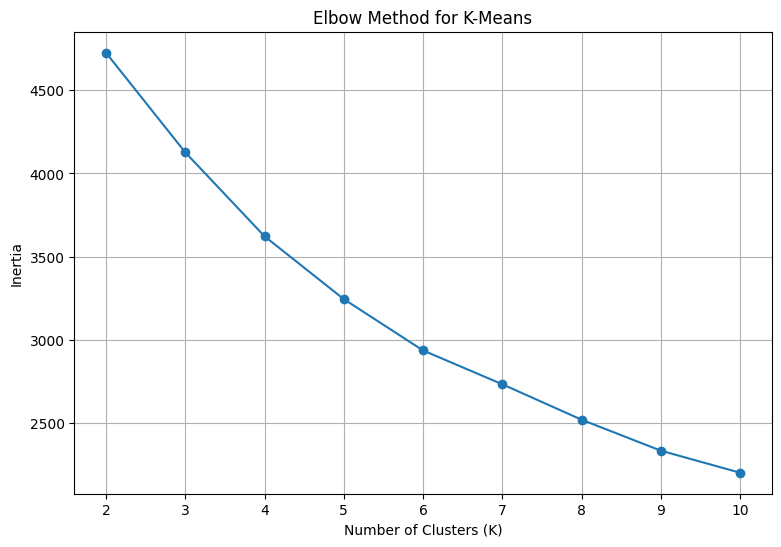

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Create a fresh empty list
inertia = []

# K values from 2 to 10
K_range = range(2, 11)

# Calculate inertia for each K
for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

# Check the values
print("K values:", list(K_range))
print("Inertia values:", inertia)

# Plot Elbow graph
plt.figure(figsize=(9, 6))

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")

plt.xticks(list(K_range))
plt.grid(True)

plt.show()

| Technique               | Project Question                                          | Main Answer                                                |
| ----------------------- | --------------------------------------------------------- | ---------------------------------------------------------- |
| **Probability**         | What is the probability of >8 hours absenteeism?          | Approximately **8.5%**                                     |
| **Sampling**            | How can we create a representative sample?                | Use **stratified sampling by Education**                   |
| **T-Test**              | Is average absence different from 8 hours?                | **Yes, statistically significant**; p ≈ 0.0285             |
| **Chi-Square**          | Is social drinking associated with high absenteeism?      | **Significant association**; p ≈ 0.00033                   |
| **Linear Regression**   | Can employee characteristics predict exact absence hours? | Limited predictive power with selected numerical variables |
| **Logistic Regression** | Can we classify high/low absenteeism?                     | Example accuracy ≈ **62%**                                 |
| **KNN**                 | Can similar employees classify absenteeism?               | Example accuracy ≈ **62%** for k=5                         |
| **K-Means**             | Can employees be segmented into groups?                   | Yes; 3 clusters can be explored using the Elbow Method     |


Final conclusion

The strongest part of this project is that one dataset is used from beginning to end. You move from:

Data → Probability → Sampling → Hypothesis Testing → Chi-Square → Regression → Classification → KNN → K-Means → Business Insights

This makes it a good Applied Statistical Analysis + Machine Learning project rather than a collection of unrelated exercises.